In [1]:
import os
import numpy as np
import pandas as pd
import xarray as xr

In [2]:
def get_isca_indices(filepath, target_wvl):
    """
    Parses isca.dat to get the boolean mask for the target wavelength
    and the corresponding Dmax values.
    """
    if not os.path.exists(filepath):
        print(f"Error: {filepath} not found.")
        return None, None, None

    try:
        # Read isca.dat (Has columns: Wvl, Dmax, Vol, Area, Qext, SSA, Asym)
        df = pd.read_csv(filepath, sep='\s+', header=None, comment='#')
        
        # Create Boolean Mask for the target wavelength
        # This mask identifies WHICH rows in the file belong to 532 o 1064 nm
        mask = np.isclose(df[0], target_wvl, atol=WVL_TOLERANCE)
        
        # Extract the data for this habit/roughness
        # Columns in file: 0=Wvl, 1=Dmax, 2=Vol, 3=Area, 4=Qext, 5=SSA, 6=Asym
        df_sub = df[mask]
        
        if df_sub.empty:
            return None, None, None
            
        dmax = df_sub[1].values
        
        # Slice data columns (2 through 6)
        data = df_sub.iloc[:, 2:].values 
        
        # We need the original boolean mask (length of entire file) for P-files
        return mask, dmax, data
        
    except Exception as e:
        print(f"Error reading isca.dat: {e}")
        return None, None, None

def read_phase_file(filepath, mask):
    """
    Reads a P*.dat file using the mask from isca.dat.
    """
    if not os.path.exists(filepath):
        return None, None

    try:
        # 1. Read the Angles (Header Line)
        with open(filepath, 'r') as f:
            header_line = f.readline()
            angles = np.array([float(x) for x in header_line.split()])
        
        # 2. Read the Body (Skipping header)
        # The file has no metadata columns, just 498 floats per line
        df_p = pd.read_csv(filepath, sep='\s+', header=None, skiprows=1)
        
        # Safety Check: Does row count match isca.dat?
        if len(df_p) != len(mask):
            print(f"Error: Row count mismatch in {os.path.basename(filepath)}. isca={len(mask)}, P={len(df_p)}")
            return None, None

        # 3. Apply Mask
        # Select only the rows corresponding to TARGET_WVL
        data_subset = df_p[mask].values
        
        return angles, data_subset

    except Exception as e:
        print(f"Error reading {filepath}: {e}")
        return None, None

def process_habit_to_netcdf(habit_name, save_dir=None, verbose=True):
    print(f"--- Processing Habit: {habit_name} ---")
    
    # Dictionary to collect data across roughness levels
    # Integral keys: 'Volume', 'Area', 'Q_ext', 'SSA', 'Asym_g'
    # Matrix keys: 'P11', 'P12', 'P22', 'P33', 'P43', 'P44'
    coll = {k: [] for k in ['Volume', 'Area', 'Q_ext', 'SSA', 'Asym_g'] + 
                           [p.replace('.dat','') for p in PHASE_FILES]}
    
    common_dmax = None
    common_angles = None
    
    for rough in ROUGHNESS_LEVELS:
        base_path = os.path.join(ROOT_DIR, habit_name, rough)
        
        # 1. READ ISCA (The Master Index)
        mask, dmax, isca_data = get_isca_indices(os.path.join(base_path, 'isca.dat'), TARGET_WVL)
        
        if mask is None:
            raise ValueError(f"Failed to find data for {TARGET_WVL} um in {rough}/isca.dat")
            
        if common_dmax is None:
            common_dmax = dmax
        elif not np.allclose(common_dmax, dmax):
            raise ValueError(f"Dmax grid mismatch in {rough}")
            
        # Store Integral Vars (Cols: Vol, Area, Qext, SSA, Asym)
        coll['Volume'].append(isca_data[:, 0])
        coll['Area'].append(isca_data[:, 1])
        coll['Q_ext'].append(isca_data[:, 2])
        coll['SSA'].append(isca_data[:, 3])
        coll['Asym_g'].append(isca_data[:, 4])
        
        # 2. READ PHASE FILES
        for p_file in PHASE_FILES:
            if verbose:
                print(f"   Extracting {rough} data for {p_file}")
            key = p_file.replace('.dat', '')
            angles, p_data = read_phase_file(os.path.join(base_path, p_file), mask)
            
            if p_data is None:
                print(f"Warning: Missing/Bad {key} for {rough}, filling NaNs.")
                # Fallback: create NaN array of correct shape
                n_ang = 498 if common_angles is None else len(common_angles)
                coll[key].append(np.full((len(dmax), n_ang), np.nan))
            else:
                if common_angles is None:
                    common_angles = angles
                coll[key].append(p_data)

    # --- BUILD DATASET ---
    coords = {
        'roughness': [float(rlvl[-3:])/100. for rlvl in ROUGHNESS_LEVELS],#ROUGHNESS_LEVELS,
        'dmax': common_dmax,
        'angle': common_angles
    }
    
    # Process Integral Arrays (Shape: Roughness x Dmax)
    area_arr = np.array(coll['Area'])
    qext_arr = np.array(coll['Q_ext'])
    ssa_arr  = np.array(coll['SSA'])
    
    # Derived Cross Sections (C = Q * Area)
    c_ext = qext_arr * area_arr
    c_sca = c_ext * ssa_arr
    c_abs = c_ext * (1.0 - ssa_arr)
    
    data_vars = {}
    data_vars['C_ext'] = xr.DataArray(
        data = c_ext, dims = ['roughness', 'dmax'],
        attrs = {'long_name': 'Extinction Cross Section'}
    )
    data_vars['C_sca'] = xr.DataArray(
        data = c_sca, dims = ['roughness', 'dmax'],
        attrs = {'long_name': 'Scattering Cross Section'}
    )
    data_vars['C_abs'] = xr.DataArray(
        data = c_abs, dims = ['roughness', 'dmax'],
        attrs = {'long_name': 'Absorption Cross Section'}
    )
    data_vars['Asym_g'] = xr.DataArray(
        data = np.array(coll['Asym_g']), dims = ['roughness', 'dmax'],
        attrs = {'long_name': 'Asymmetry Parameter'}
    )
    data_vars['Volume'] = xr.DataArray(
        data = np.array(coll['Volume']), dims = ['roughness', 'dmax'],
        attrs = {'long_name': 'Volume'}
    )
    data_vars['Projected_Area'] = xr.DataArray(
        data = area_arr, dims = ['roughness', 'dmax'],
        attrs = {'long_name': 'Projected Area'}
    )

    # Process Matrix Arrays (Shape: Roughness x Dmax x Angle)
    p11_arr = np.array(coll['P11']) 
    data_vars['P11'] = xr.DataArray(
        data = p11_arr, dims = ['roughness', 'dmax', 'angle'],
        attrs = {'long_name': 'Scattering Phase Function'}
    )
    
    # De-normalization Loop
    for k in ['P12', 'P22', 'P33', 'P43', 'P44']:
        long_names = {
            'P12': 'Degree of Linear Polarization',
            'P22': 'Polarization Parallel Component',
            'P33': 'Circular Polarization',
            'P43': 'Linear to Circular Conversion',
            'P44': 'Circular Polarization Component'
        }
        norm_arr = np.array(coll[k])
        # P_physical = (P_norm) * P11
        denorm_arr = norm_arr * p11_arr
        data_vars[k] = xr.DataArray(
            data = denorm_arr, dims = ['roughness', 'dmax', 'angle'],
            attrs = {'long_name': long_names[k]}
        )

    ds = xr.Dataset(data_vars, coords=coords)
    
    # Metadata
    ds.attrs = {
        'habit': habit_name,
        'wavelength': f'{TARGET_WVL} microns',
        'source': 'Yang et al. (2013)',
        'description': 'Phase elements P12-P44 are de-normalized (multiplied by P11)'
    }
    ds['angle'].attrs = {'units': 'degrees', 'long_name': 'Scattering Angle'}
    ds['dmax'].attrs = {'units': 'microns', 'long_name': 'Maximum Dimension'}
    ds['roughness'].attrs = {
        'long_name': 'Surface Roughness',
        'description': '0: smooth, 0.03: moderate, 0.5: severe'
    }

    if save_dir:
        out_file = f'{save_dir}/Yang2013_Ice_{int(1e3*TARGET_WVL)}nm_{habit_name}.nc'
        ds.to_netcdf(out_file)
        print(f"Success! Saved {out_file}")
    return ds

## Test on Single Habit

In [7]:
# --- CONFIGURATION ---
ROOT_DIR = '/home/jfinlon/data/IMPACTS/Particle_Properties_DB/Data_0.2_15.25'
TARGET_WVL = 0.532 #1.064
WVL_TOLERANCE = 5e-3
ROUGHNESS_LEVELS = ['Rough000', 'Rough003', 'Rough050']
PHASE_FILES = ['P11.dat', 'P12.dat', 'P22.dat', 'P33.dat', 'P43.dat', 'P44.dat']

# --- EXECUTION ---
# Example usage:
habit_input = 'single_column'
# habit_input = input("Enter habit name (e.g., 10_plates, droxtal, solid_column): ").strip()
# try:
ds = process_habit_to_netcdf(habit_input, save_dir=None)
# except Exception as e:
#     print(f"Failed: {e}")

--- Processing Habit: single_column ---
   Extracting Rough000 data for P11.dat
   Extracting Rough000 data for P12.dat
   Extracting Rough000 data for P22.dat
   Extracting Rough000 data for P33.dat
   Extracting Rough000 data for P43.dat
   Extracting Rough000 data for P44.dat
   Extracting Rough003 data for P11.dat
   Extracting Rough003 data for P12.dat
   Extracting Rough003 data for P22.dat
   Extracting Rough003 data for P33.dat
   Extracting Rough003 data for P43.dat
   Extracting Rough003 data for P44.dat
   Extracting Rough050 data for P11.dat
   Extracting Rough050 data for P12.dat
   Extracting Rough050 data for P22.dat
   Extracting Rough050 data for P33.dat
   Extracting Rough050 data for P43.dat
   Extracting Rough050 data for P44.dat


In [8]:
ds

<xarray.Dataset> Size: 14MB
Dimensions:         (roughness: 3, dmax: 189, angle: 498)
Coordinates:
  * roughness       (roughness) float64 24B 0.0 0.03 0.5
  * dmax            (dmax) float64 2kB 2.0 3.0 4.0 ... 9.75e+03 9.875e+03 1e+04
  * angle           (angle) float64 4kB 0.0 0.01 0.02 0.03 ... 179.5 179.8 180.0
Data variables:
    C_ext           (roughness, dmax) float64 5kB 6.985 10.88 ... 1.07e+07
    C_sca           (roughness, dmax) float64 5kB 6.985 10.88 ... 1.07e+07
    C_abs           (roughness, dmax) float64 5kB 1.397e-07 4.351e-07 ... 0.0
    Asym_g          (roughness, dmax) float64 5kB 0.8095 0.7148 ... 0.846 0.8461
    Volume          (roughness, dmax) float64 5kB 2.546 8.593 ... 3.146e+09
    Projected_Area  (roughness, dmax) float64 5kB 2.737 6.157 ... 5.377e+06
    P11             (roughness, dmax, angle) float64 2MB 87.96 87.96 ... 0.08742
    P12             (roughness, dmax, angle) float64 2MB 0.0 2.532e-05 ... 0.0
    P22             (roughness, dmax, angle) float64 2MB 87.94 87.93 ... 0.04027
    P33             (roughness, dmax, angle) float64 2MB 87.94 ... -0.04027
    P43             (roughness, dmax, angle) float64 2MB 0.0 -6.599e-05 ... 0.0
    P44             (roughness, dmax, angle) float64 2MB 87.91 87.9 ... 0.006887
Attributes:
    habit:        single_column
    wavelength:   0.532 microns
    source:       Yang et al. (2013)
    description:  Phase elements P12-P44 are de-normalized (multiplied by P11)

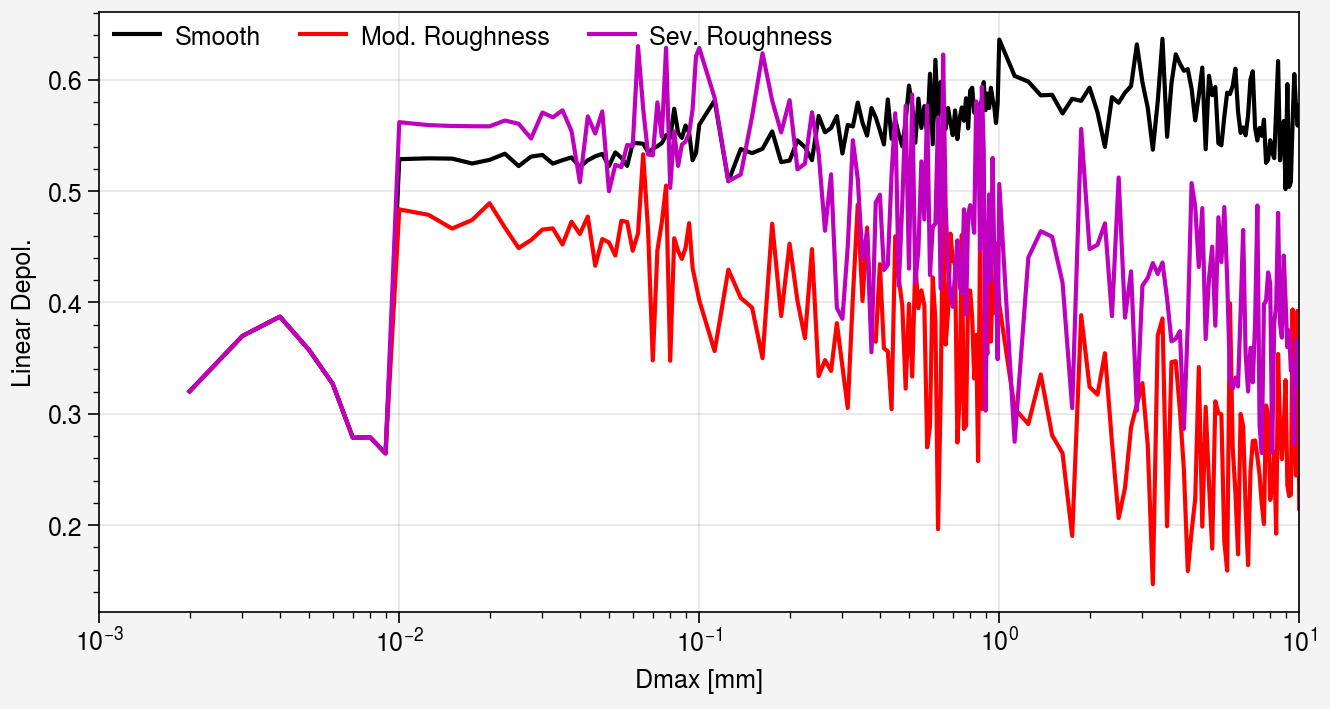

In [9]:
import ultraplot as uplt

ds_rough1 = ds.sel(roughness=0., angle=180.)
ds_rough2 = ds.sel(roughness=0.03, angle=180.)
ds_rough3 = ds.sel(roughness=0.5, angle=180.)

fig, ax = uplt.subplots(refwidth=6, refaspect=2)
ax.plot(
    ds_rough1.dmax / 1000.,
    (ds_rough1.P11 - ds_rough1.P22) / (ds_rough1.P11 + ds_rough1.P22)
    , 'k-', label='Smooth'
)
ax.plot(
    ds_rough2.dmax / 1000.,
    (ds_rough2.P11 - ds_rough2.P22) / (ds_rough2.P11 + ds_rough2.P22)
    , 'r-', label='Mod. Roughness'
)
ax.plot(
    ds_rough3.dmax / 1000.,
    (ds_rough3.P11 - ds_rough3.P22) / (ds_rough3.P11 + ds_rough3.P22)
    , 'm-', label='Sev. Roughness'
)
ax.legend(loc='ul', ncols=3, frame=False)
ax.format(
    xlim=(1e-3, 10), xscale='log', xformatter='log', xlabel='Dmax [mm]',
    ylabel='Linear Depol.'
)

## Run on All Habits

In [3]:
# --- CONFIGURATION ---
ROOT_DIR = '/home/jfinlon/data/IMPACTS/Particle_Properties_DB/Data_0.2_15.25'
TARGET_WVL = 0.532 #1.064
WVL_TOLERANCE = 5e-3
ROUGHNESS_LEVELS = ['Rough000', 'Rough003', 'Rough050']
PHASE_FILES = ['P11.dat', 'P12.dat', 'P22.dat', 'P33.dat', 'P43.dat', 'P44.dat']

# --- EXECUTION ---
save_dir = '/home/jfinlon/data/IMPACTS/Particle_Properties_DB'
habits = [
    'single_column', 'plate',
    'hollow_column', 'droxtal', 'HBR', 'SBR',
    '8_columns', '5_plates', '10_plates'
]
for habit_input in habits:
    _ = process_habit_to_netcdf(habit_input, save_dir=save_dir, verbose=False)

--- Processing Habit: single_column ---
Success! Saved /home/jfinlon/data/IMPACTS/Particle_Properties_DB/Yang2013_Ice_532nm_single_column.nc
--- Processing Habit: plate ---
Success! Saved /home/jfinlon/data/IMPACTS/Particle_Properties_DB/Yang2013_Ice_532nm_plate.nc
